# Neuromodulator signals in each DDM-HMM state

The question here is what the recorded neuromodulator does across the trial's epochs, with one trace per DDM-HMM state.

**What the export holds**: `pose_qc_hmm_k4` stores only peri-event snippets of the preprocessed (z-scored) GCaMP signal, −1 to +1 s around **stimulus onset** (`stimOnTrigger_times`) and around **feedback**, at 30 Hz. There is no continuous trace, so the trial cannot be time-warped. It is shown as two windows, each aligned to an epoch edge, with a gap between them. The x axis has the same length on every trial, and nothing is stretched.

| window | covers |
|---|---|
| stimulus −1 → 0 s | the end of Pre-quiescence, then Quiescence (its own length, `quiescencePeriod`, about 0.4–0.7 s) |
| stimulus 0 → +1 s | the start of the Choice epoch |
| feedback −1 → 0 s | the end of the Choice epoch |
| feedback 0 → +1 s | the start of the ITI |

**Masking, per trial**: in the stimulus window, samples after that trial's feedback and before its trial start are blanked. In the feedback window, samples before stimulus onset and after the trial end are blanked. The two windows never show the same samples twice, and no sample belongs to a neighbouring trial. On fast trials, the late stimulus window and early feedback window therefore average over fewer trials.

**No baseline subtraction** by default (`BASELINE = False`). Pre-stimulus differences between states are part of the question, and subtracting the −0.1–0 s mean would remove them. Set it to True to get the repo's convention.

**Outcome is split** into rewarded and error trials, because states differ a lot in accuracy and the feedback response depends on reward.

There are 7 mice with a DDM-HMM fit and one fiber per session: DR-5HT ×2, VTA-DA ×2, SNc-DA ×1, LC-NE ×2. NBM-ACh has no fit.

In [1]:
import sys, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'ddm_hmm.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / 'paper-individuality'))
from Functions import ddm_hmm as dh
from Functions import event_psth as ep
import paper_style as ps
ps.use('paper')
warnings.filterwarnings('ignore', message='Mean of empty slice')   # fully masked samples
warnings.filterwarnings('ignore', message='Degrees of freedom')

K = 4
EXCLUDE = ['ZFM-06271']   # one session
BASELINE = False          # True: subtract each trial's mean over stimulus -0.1..0 s from both windows
MIN_TRIALS = 20           # a (session, state, outcome) cell needs this many trials to contribute

trials, params = dh.load_all(K)
labels = dh.state_labels(trials, params)
d = dh.go_trials(trials)
d = d[~d['subject'].isin(EXCLUDE)].merge(labels[['subject', 'state', 'label', 'tag']], on=['subject', 'state'])
rec = pd.read_csv(dh.ARCHIVE / 'recordings.csv')
rec = rec[rec['eid'].isin(d['eid'])]
print(rec.groupby(['target_NM', 'subject', 'brain_region']).size().rename('sessions'))

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


target_NM  subject    brain_region
DR-5HT     ZFM-09365  DR              43
           ZFM-09439  DR              41
LC-NE      ZFM-08776  LC              33
           ZFM-08871  LC              35
SNc-DA     ZFM-04019  SNc             20
VTA-DA     ZFM-08818  VTA             21
           ZFM-09394  VTA-r           46
Name: sessions, dtype: int64


## Per-trial traces, masked to their own trial and epoch

In [2]:
STIM, FB, meta = ep.photometry_windows(rec, d, baseline=BASELINE)   # Functions/event_psth.py
TIME = ep.TIME
assert meta['state'].notna().all()
print(f'{len(meta):,} trials with a trace; per outcome:', meta['correct'].value_counts().to_dict())

190,223 trials with a trace; per outcome: {1.0: 143725, 0.0: 46498}


## Plotting: two windows with a gap

`split_panels` (in `Functions/event_psth.py`, shared with the syllable notebook) draws one row: stimulus-aligned on the left and feedback-aligned on the right, at equal widths, with a break mark between them. Epoch bands sit at the top. The Quiescence band starts at the median `quiescencePeriod`, so its left edge is approximate on any single trial. `group_traces` averages trials within each session and then across sessions, with SEM across sessions. Every session gets equal weight.

In [3]:
QP = float(meta['quiescencePeriod'].median())

def group_traces(m, by):
    # mean +- SEM across sessions of the per-session mean trace, per value of `by`
    out = {}
    for key, g in m.groupby(by):
        sess_s, sess_f = [], []
        for _, gs in g.groupby('eid'):
            if len(gs) < MIN_TRIALS:
                continue
            idx = gs.index.to_numpy()
            sess_s.append(np.nanmean(STIM[idx], axis=0)); sess_f.append(np.nanmean(FB[idx], axis=0))
        if len(sess_s) < 2:
            continue
        S, F = np.vstack(sess_s), np.vstack(sess_f)
        sem = lambda X: np.nanstd(X, axis=0, ddof=1) / np.sqrt(np.sum(~np.isnan(X), axis=0))
        out[key] = dict(stim=(np.nanmean(S, 0), sem(S)), fb=(np.nanmean(F, 0), sem(F)),
                        n_sessions=len(S), n_trials=len(g))
    return out

def split_panels(fig, spec, title=None, epochs=True):
    return ep.split_panels(fig, spec, title, epochs, qp=QP)

def draw(a, b, traces, style):
    for key, tr in traces.items():
        st = style(key)
        for ax, w in [(a, 'stim'), (b, 'fb')]:
            mu, se = tr[w]
            ax.fill_between(TIME, mu - se, mu + se, color=st['color'], alpha=0.2, lw=0)
            ax.plot(TIME, mu, lw=1.1, **st)
    lo = min(ax.get_ylim()[0] for ax in (a, b)); hi = max(ax.get_ylim()[1] for ax in (a, b))
    pad = 0.12 * (hi - lo)
    for ax in (a, b):
        ax.set_ylim(lo, hi + pad)

STYLES = ['-', '--', ':', '-.']
def state_style(mouse):
    s = labels[labels['subject'] == mouse].sort_values('state')
    seen, out = {}, {}
    for _, r in s.iterrows():
        i = seen.get(r['label'], 0); seen[r['label']] = i + 1
        out[r['state']] = dict(color=dh.LABEL_COLORS[r['label']], ls=STYLES[i % 4], label=r['tag'])
    return lambda k: out[k]

## Mouse by mouse: one trace per DDM-HMM state

Each row is one mouse, grouped by neuromodulator. The left pair shows rewarded trials and the right pair shows error trials. States that share a name within a mouse are told apart by line style. y is the z-scored GCaMP signal.

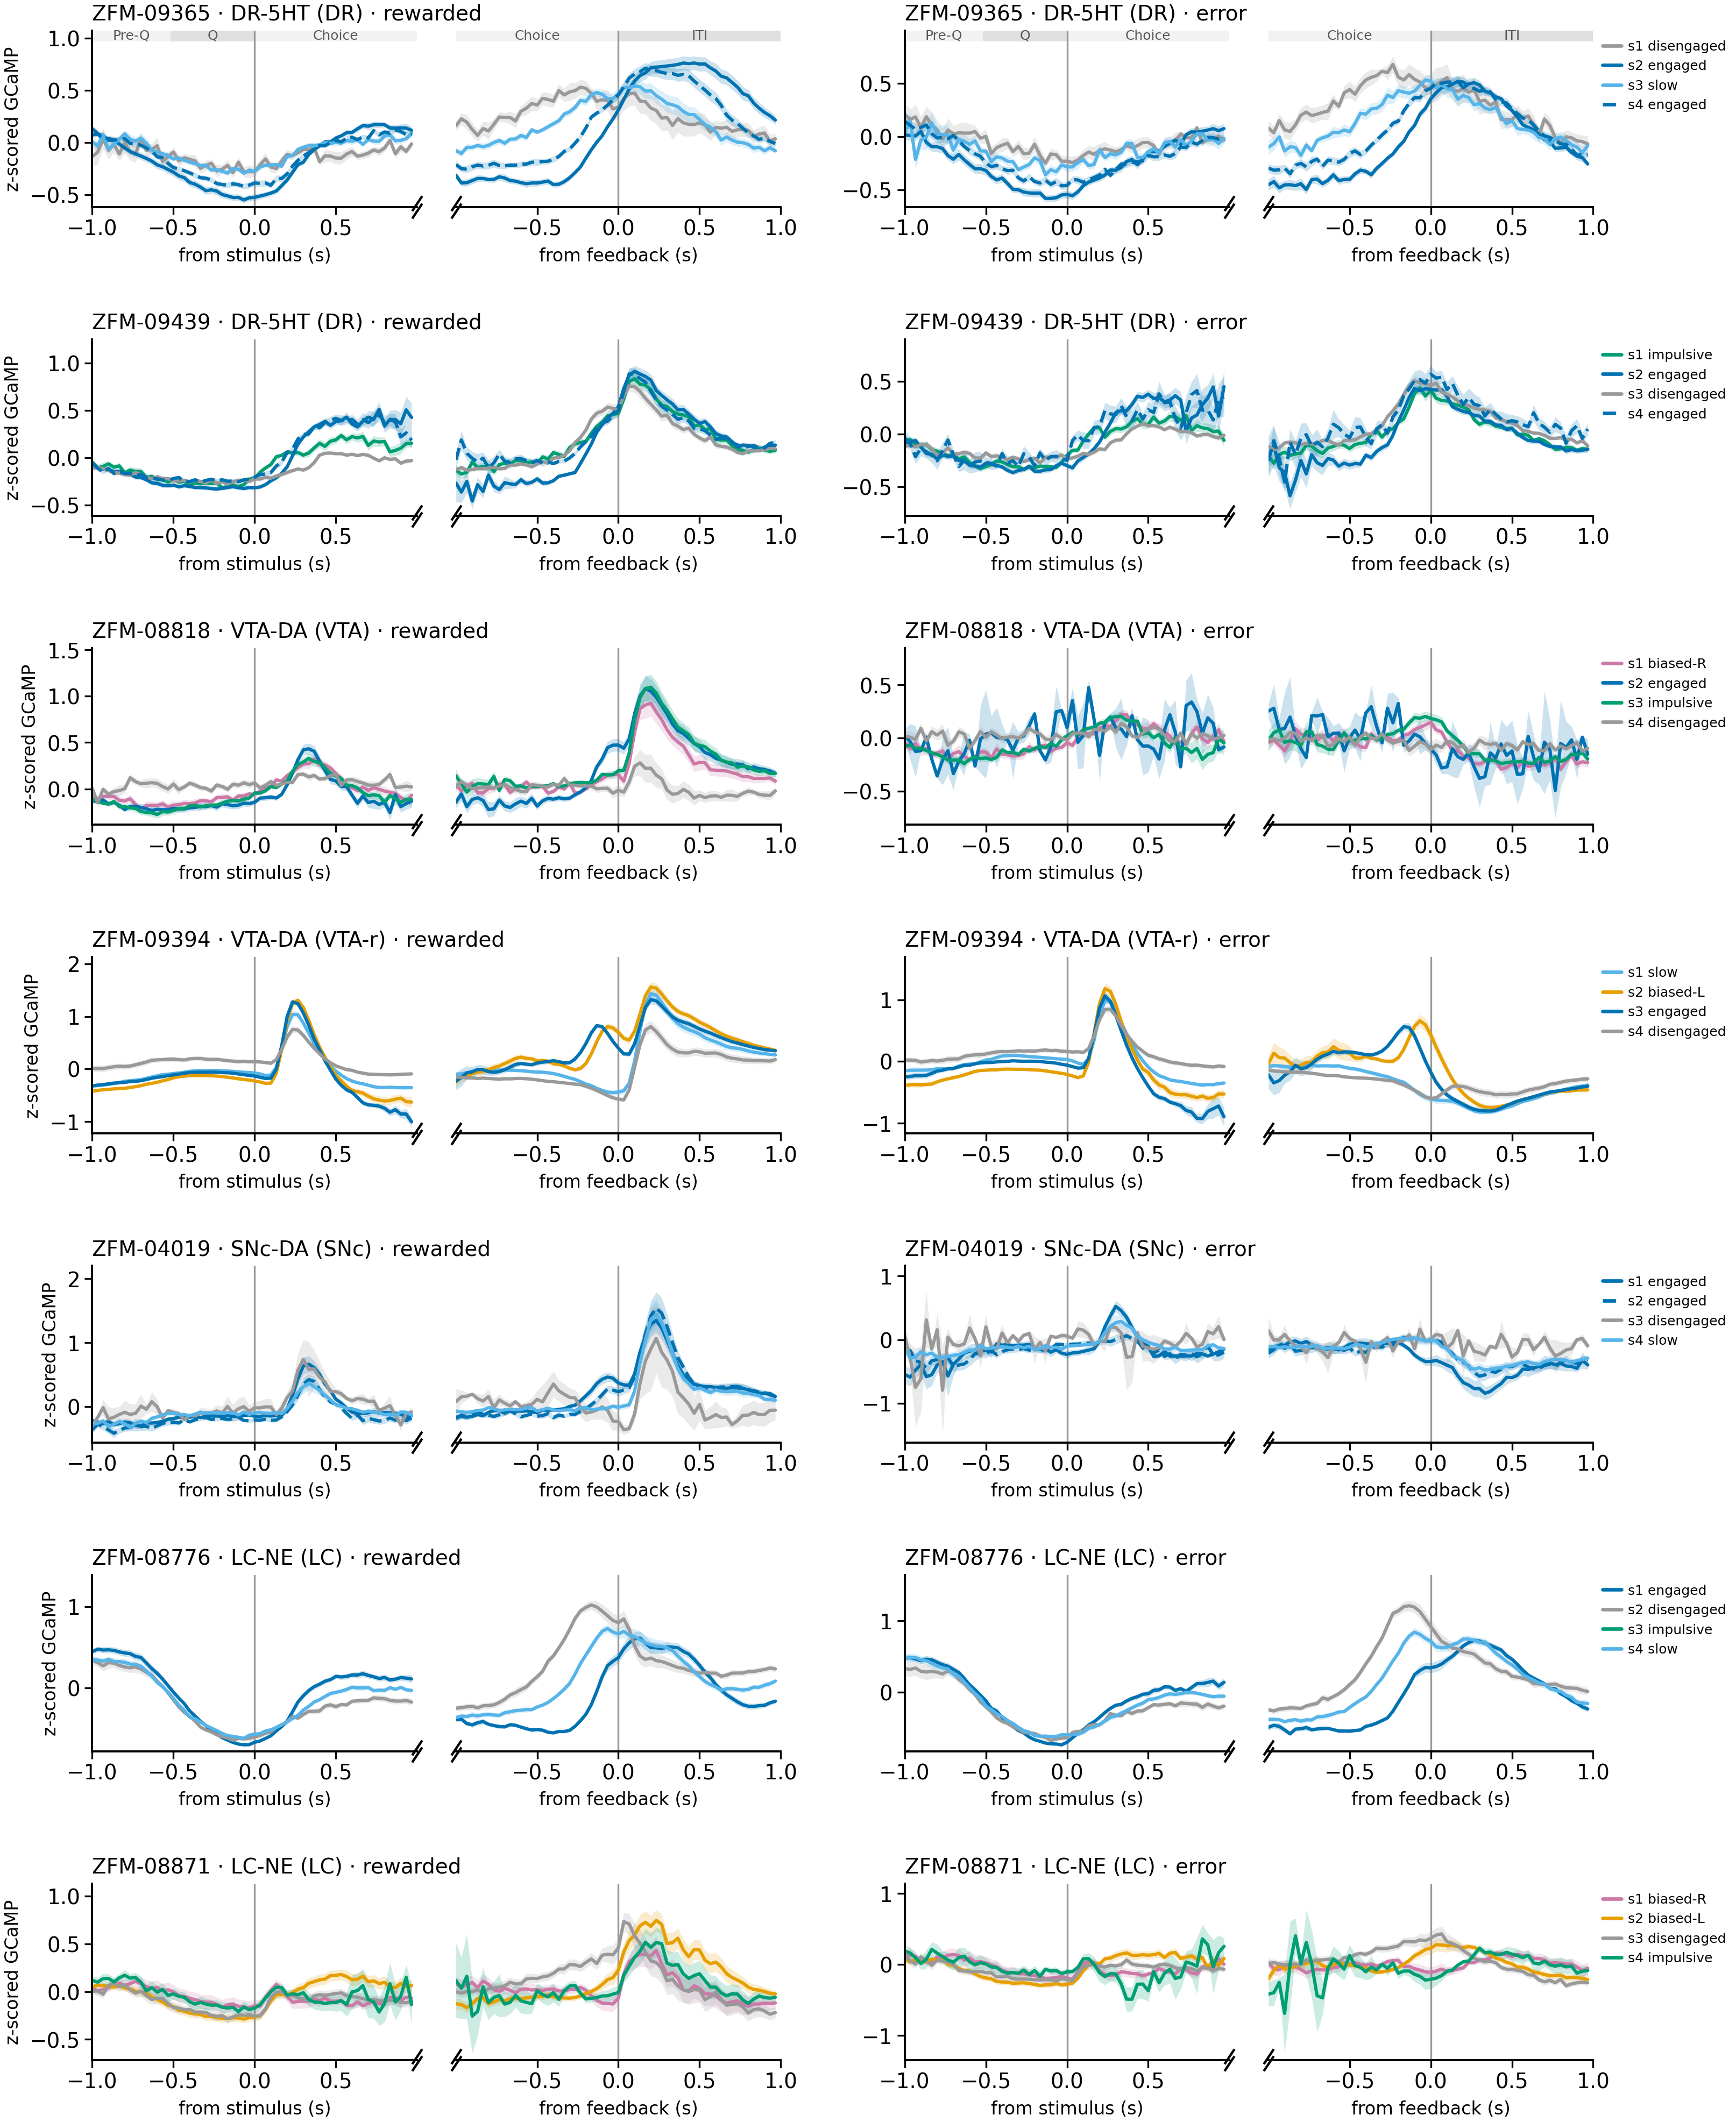

In [4]:
NM_ORDER = ['DR-5HT', 'VTA-DA', 'SNc-DA', 'LC-NE']
mice = (meta.drop_duplicates('subject').assign(o=lambda x: x['target_NM'].map(NM_ORDER.index))
        .sort_values(['o', 'subject'])[['subject', 'target_NM', 'region']].to_numpy())
fig = plt.figure(figsize=(9, 1.75 * len(mice)))
outer = fig.add_gridspec(len(mice), 2, wspace=0.18, hspace=0.75)
for row, (mouse, nm, region) in enumerate(mice):
    style = state_style(mouse)
    for col, (outcome, oname) in enumerate([(1, 'rewarded'), (0, 'error')]):
        m = meta[(meta['subject'] == mouse) & (meta['correct'] == outcome)]
        a, b = split_panels(fig, outer[row, col], f'{mouse} · {nm} ({region}) · {oname}', epochs=(row == 0))
        draw(a, b, group_traces(m, 'state'), style)
        if col == 0:
            a.set_ylabel('z-scored GCaMP', fontsize=6)
        if col == 1:
            b.legend(handles=[Line2D([], [], **style(s)) for s in sorted(m['state'].unique())],
                     fontsize=4.5, frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))
plt.show()

## Pooled by state kind, per neuromodulator

Here every trial of a mouse in states of the same name is pooled. A mouse with two engaged states contributes both to 'engaged'. Then sessions of all mice of that neuromodulator are averaged, with SEM across sessions. With 1–2 mice per neuromodulator this is a description, not a test. A kind present in only one mouse is that mouse's curve.

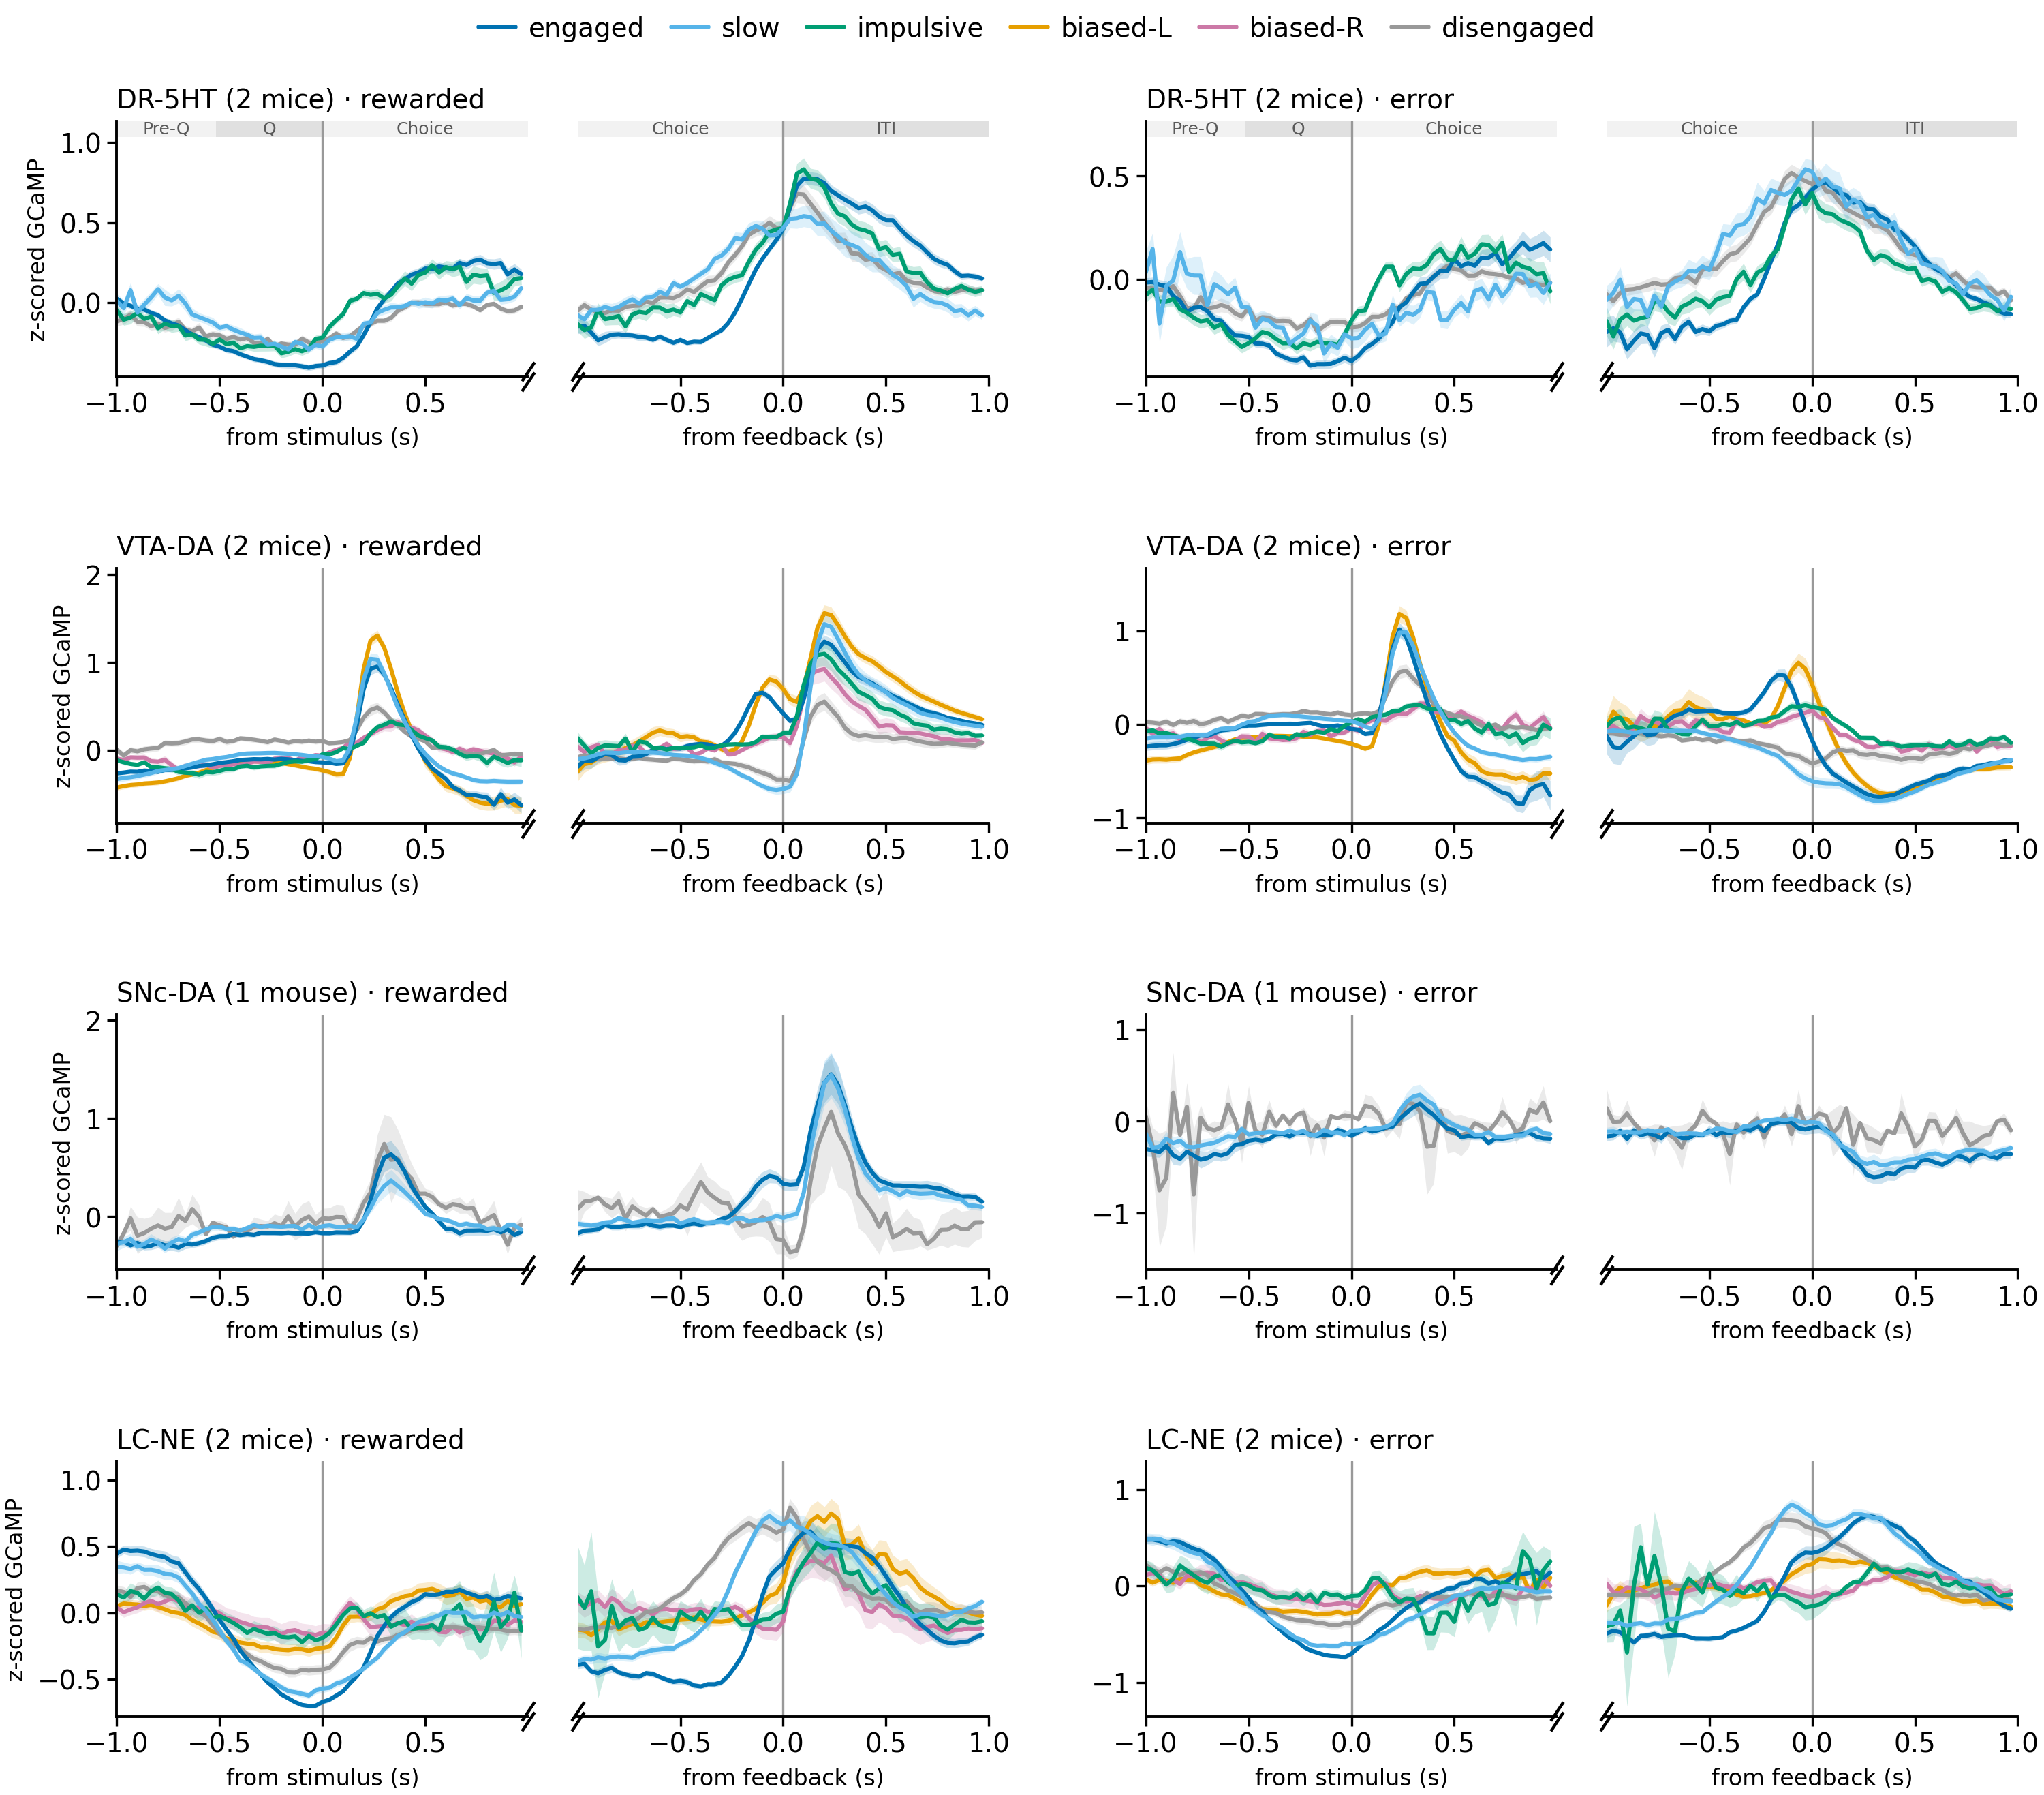

In [5]:
fig = plt.figure(figsize=(9, 1.9 * len(NM_ORDER)))
outer = fig.add_gridspec(len(NM_ORDER), 2, wspace=0.18, hspace=0.75)
kind_style = lambda k: dict(color=dh.LABEL_COLORS[k], ls='-', label=k)
for row, nm in enumerate(NM_ORDER):
    nmice = meta.loc[meta['target_NM'] == nm, 'subject'].nunique()
    for col, (outcome, oname) in enumerate([(1, 'rewarded'), (0, 'error')]):
        m = meta[(meta['target_NM'] == nm) & (meta['correct'] == outcome)]
        a, b = split_panels(fig, outer[row, col], f"{nm} ({nmice} {'mouse' if nmice == 1 else 'mice'}) · {oname}", epochs=(row == 0))
        draw(a, b, group_traces(m, 'label'), kind_style)
        if col == 0:
            a.set_ylabel('z-scored GCaMP', fontsize=6)
kinds = [k for k in dh.LABEL_COLORS if k in set(meta['label'])]
fig.legend(handles=[Line2D([], [], **kind_style(k)) for k in kinds], loc='upper center', ncol=len(kinds),
           frameon=False, bbox_to_anchor=(0.5, 0.94))
plt.show()

## Pooled across mice, with the mouse taken out

The pooled view above mixes mouse identity into state. For example, the LC dip during Quiescence belongs to ZFM-08776 in every state, and only looks like an engaged/slow effect because those states come from that mouse.

The fix is to compare each state with its own session:
1. In every session and outcome, take the mean trace over **all** of that session's trials (every state).
2. Subtract it from each state's mean trace in that session. A state's curve is now *how this state differs from the same session's average*. Mouse identity, fiber placement, and between-session drift all cancel.
3. Average those deviations over each mouse's sessions, then give each mouse equal weight.

The band is SEM across mice where a state kind exists in 2 or more mice; otherwise it is SEM across that one mouse's sessions (dashed outline). The legend gives the number of mice per kind. The bottom row pools all 7 mice across neuromodulators. That row only makes sense where the neuromodulators move in the same direction, so read it alongside the rows above it.

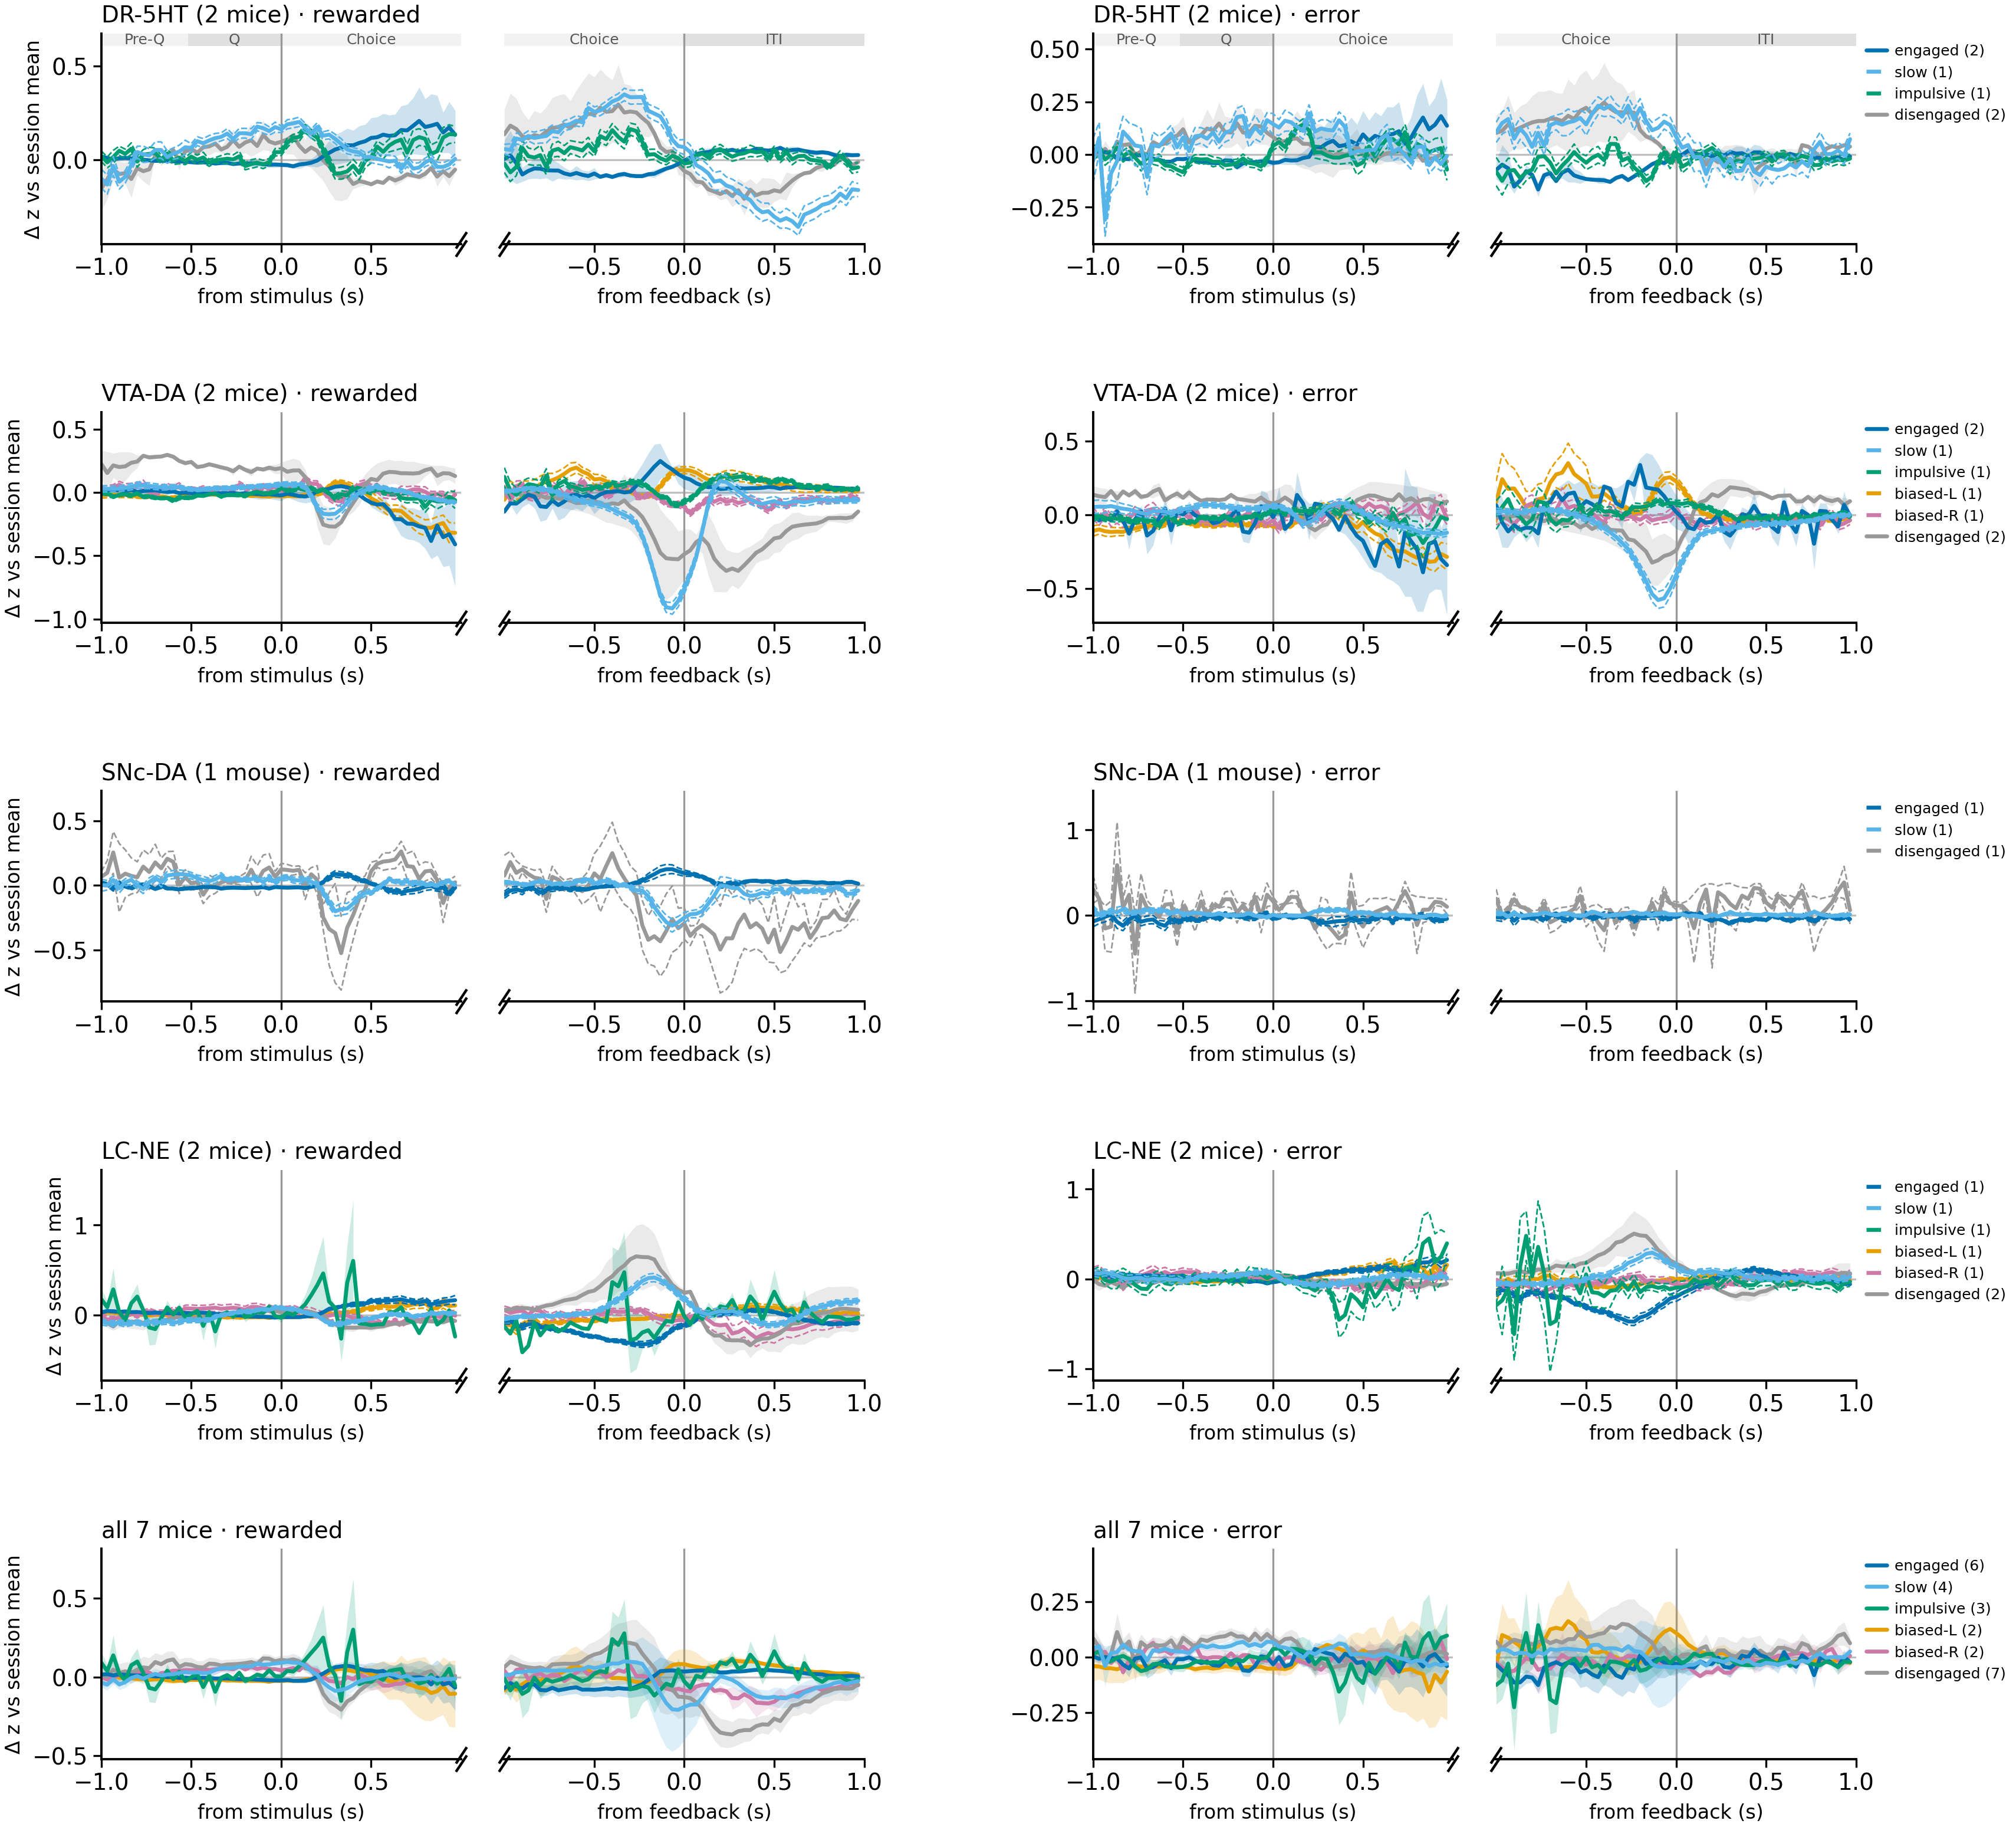

In [6]:
def deviation_traces(m, by='label'):
    # per session: (state-kind mean) - (all-trial session mean); then mouse means; then mean over mice
    per_mouse = {}   # (kind, mouse) -> list of (stim_dev, fb_dev)
    for (mouse, eid), g in m.groupby(['subject', 'eid']):
        idx_all = g.index.to_numpy()
        s0, f0 = np.nanmean(STIM[idx_all], 0), np.nanmean(FB[idx_all], 0)
        for kind, gk in g.groupby(by):
            if len(gk) < MIN_TRIALS:
                continue
            idx = gk.index.to_numpy()
            per_mouse.setdefault((kind, mouse), []).append((np.nanmean(STIM[idx], 0) - s0, np.nanmean(FB[idx], 0) - f0))
    out = {}
    sem = lambda X: np.nanstd(X, axis=0, ddof=1) / np.sqrt(np.sum(~np.isnan(X), axis=0))
    for kind in sorted({k for k, _ in per_mouse}):
        mice_k = [mm for k, mm in per_mouse if k == kind]
        S = {mm: np.vstack([x[0] for x in per_mouse[(kind, mm)]]) for mm in mice_k}
        F = {mm: np.vstack([x[1] for x in per_mouse[(kind, mm)]]) for mm in mice_k}
        if len(mice_k) >= 2:
            Sm = np.vstack([np.nanmean(S[mm], 0) for mm in mice_k]); Fm = np.vstack([np.nanmean(F[mm], 0) for mm in mice_k])
            stim, fb, across = (np.nanmean(Sm, 0), sem(Sm)), (np.nanmean(Fm, 0), sem(Fm)), 'mice'
        else:
            mm = mice_k[0]
            if len(S[mm]) < 2:
                continue
            stim, fb, across = (np.nanmean(S[mm], 0), sem(S[mm])), (np.nanmean(F[mm], 0), sem(F[mm])), 'sessions'
        out[kind] = dict(stim=stim, fb=fb, n_mice=len(mice_k), across=across)
    return out

def draw_dev(a, b, traces):
    for kind, tr in traces.items():
        c = dh.LABEL_COLORS[kind]
        for ax, w in [(a, 'stim'), (b, 'fb')]:
            mu, se = tr[w]
            if tr['across'] == 'mice':
                ax.fill_between(TIME, mu - se, mu + se, color=c, alpha=0.2, lw=0)
            else:   # one mouse: band is across its sessions, drawn as an outline
                ax.plot(TIME, mu - se, color=c, lw=0.5, ls='--'); ax.plot(TIME, mu + se, color=c, lw=0.5, ls='--')
            ax.plot(TIME, mu, color=c, lw=1.2)
    for ax in (a, b):
        ax.axhline(0, color='0.75', lw=0.6, zorder=0)
    lo = min(ax.get_ylim()[0] for ax in (a, b)); hi = max(ax.get_ylim()[1] for ax in (a, b))
    for ax in (a, b):
        ax.set_ylim(lo, hi + 0.12 * (hi - lo))

ROWS = [(nm, meta['target_NM'] == nm) for nm in NM_ORDER] + [('all 7 mice', meta['target_NM'].notna())]
fig = plt.figure(figsize=(9.6, 1.9 * len(ROWS)))
outer = fig.add_gridspec(len(ROWS), 2, wspace=0.3, hspace=0.8)
for row, (name, mask) in enumerate(ROWS):
    nmice = meta.loc[mask, 'subject'].nunique()
    for col, (outcome, oname) in enumerate([(1, 'rewarded'), (0, 'error')]):
        m = meta[mask & (meta['correct'] == outcome)]
        title = f"{name} ({nmice} {'mouse' if nmice == 1 else 'mice'}) · {oname}" if row < len(NM_ORDER) else f'{name} · {oname}'
        a, b = split_panels(fig, outer[row, col], title, epochs=(row == 0))
        tr = deviation_traces(m)
        draw_dev(a, b, tr)
        if col == 0:
            a.set_ylabel('Δ z vs session mean', fontsize=6)
        else:
            b.legend(handles=[Line2D([], [], color=dh.LABEL_COLORS[k], lw=1.2,
                                     ls='-' if tr[k]['across'] == 'mice' else '--',
                                     label=f"{k} ({tr[k]['n_mice']})") for k in dh.LABEL_COLORS if k in tr],
                     fontsize=4.5, frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))
plt.show()

## Caveats to keep in mind

- **Time in the session.** Disengaged and slow states come late in the session, and the z-scored signal can drift within a session. A state difference in the pre-stimulus baseline may therefore partly be a time-in-session difference. One check is to restrict to the same trial-position range, e.g. `meta['trial_frac'].between(0.5, 0.9)`.
- **Reaction time.** States differ in RT, so how many trials are averaged changes along each window (see Masking above). The stimulus window after about 0.3 s is dominated by slow trials in every state.
- **Contrast.** Contrast is drawn independently of state, but within a state the rewarded and error trials have different contrast mixes. Error trials are mostly low-contrast in engaged states and mixed in disengaged states.